# NB3 -- Attack 1: PGD/FGSM Grey-Box Surrogate Transfer (Multiclass, v4)

Rebuilt against the v4 corrected pipeline from the original leakage-era
`NB3_Attack1_Drive_results.ipynb` architectural reference (Mutua et al., 2025
grey-box surrogate-transferability methodology). **Only the data pipeline and target
model source are corrected; the attack architecture (surrogate design, FGSM/PGD math,
epsilon sweep, per-class breakdown) is carried over unchanged.**

**Corrections applied vs. the original reference notebook:**
- Data: loads `phase1_data_v4.pkl` (temporal+embargo split, 43 features: 25 base + 18
  temporal) instead of the old random 80/20 stratified split on 25 features.
- Target model: **retrains the Optuna-tuned XGBoost from the actual v4 `best_params`**
  loaded from `optuna_xgboost_results_v4.pkl`, instead of hardcoding stale leakage-era
  hyperparameters. Multiclass uses the **tuned** XGBoost per the project's model
  selection (tuned won 4/5 seeds in the robustness check; baseline is used for binary
  instead -- see the binary companion notebook).
- Paths: local Windows (`C:\Users\user\Desktop\Projects\PHYSAR-NEW`), not Colab/Drive.

**Unchanged from the reference architecture:**
- `SurrogateMLP` (input -> 64 -> 32 -> n_classes), trained on **true labels** over the
  full training set (grey-box "training data: read access" capability, per Mutua et al.)
  -- not on the target's predictions.
- FGSM and PGD implementations, operating unconstrained across all features in
  standardized space (feature-restricted attacks are Attack 2/PPO's scope, not this one).
- Epsilon sweep `[0.0, 0.01, 0.05, ..., 0.45]`, per-class breakdown at eps=0.1 for both
  PGD and FGSM.
- Save structure: attack results, adversarial examples at eps=0.1 (for Defence 1 reuse),
  and the surrogate model state dict.

---

**This revision (Attack 1, baseline-model variant):** the original NB3 loads `optuna_xgboost_results_v4.pkl` and attacks the Optuna-tuned XGBoost (test F1=0.7110). During notebook verification for the dissertation, this was found to be inconsistent with Table 6.1's architecture-comparison recommendation, which selects the untuned baseline (test F1=0.7225) since Optuna tuning does not improve XGBoost's F1. This revision retargets the identical attack methodology (surrogate MLP, FGSM/PGD, epsilon sweep, per-class breakdown, 5-seed robustness, McNemar's test, bootstrap CI) at the untuned baseline model instead, using the exact hyperparameters from `2_NB1_Baseline_MultiClass_v4`. Results save to separate `*_baseline_v4.*` filenames so they don't overwrite the original tuned-model run; a comparison cell near the end contrasts both runs directly if both output files are present. The goal is to check whether the tuned-vs-baseline model choice changes any qualitative finding (which classes are physics-immune, whether immunity is budget-dependent) or only the exact evasion percentages.


## Setup

In [ ]:
import os, random
import numpy as np
import pandas as pd
import joblib
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import xgboost as xgb
from sklearn.metrics import f1_score, classification_report
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

PROJECT_DIR = r'C:\Users\user\Desktop\Projects\PHYSAR-NEW'
os.chdir(PROJECT_DIR)

RANDOM_STATE = 42
os.environ['PYTHONHASHSEED'] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
torch.cuda.manual_seed_all(RANDOM_STATE)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Working directory: {os.getcwd()}')
print(f'Device: {DEVICE}')

# GPU detection for XGBoost -- same pattern as NB2, since XGBoost silently falls back to
# CPU rather than raising when device='cuda' is requested but unavailable.
import warnings as _warnings
with _warnings.catch_warnings(record=True) as _caught:
    _warnings.simplefilter('always')
    _test_model = xgb.XGBClassifier(tree_method='hist', device='cuda', n_estimators=2)
    _test_model.fit(np.zeros((10, 2)), np.array([0, 1] * 5))
    _fell_back_to_cpu = any('No visible GPU' in str(w.message) for w in _caught)

if _fell_back_to_cpu:
    GPU_PARAMS = {}
    print('GPU not available for XGBoost (silently fell back to CPU) -- using CPU.')
else:
    GPU_PARAMS = {'tree_method': 'hist', 'device': 'cuda'}
    print('GPU detected -- XGBoost will use CUDA (tree_method=hist, device=cuda).')

Working directory: C:\Users\user\Desktop\Projects\PHYSAR-NEW
Device: cuda
GPU detected -- XGBoost will use CUDA (tree_method=hist, device=cuda).


## 1. Load Phase 1 data and the tuned XGBoost hyperparameters

Loads `phase1_data_v4.pkl` (same canonical file every v4 notebook tunes/evaluates
against) and `optuna_xgboost_results_v4.pkl` (the Optuna search's saved `best_params` --
no fitted tuned booster artifact was saved to disk, only the baseline model was, so the
tuned target model is retrained here from those params, exactly as NB2's own "fit best
model on full training set" cell does).

In [ ]:
PIPELINE_VERSION = 'v4'
EXPECTED_TEST_FRAC = 0.15
EXPECTED_EMBARGO_SECONDS = 1.0

data = joblib.load(f'phase1_data_{PIPELINE_VERSION}.pkl')

version_mismatch = (
    data.get('PIPELINE_VERSION') != PIPELINE_VERSION
    or data.get('TEST_FRAC') != EXPECTED_TEST_FRAC
    or data.get('EMBARGO_SECONDS') != EXPECTED_EMBARGO_SECONDS
)
if version_mismatch:
    print(f"WARNING: loaded file's version metadata doesn't match this notebook's "
          f"expectations -- proceeding anyway, but double check before trusting results.")
    print(f"  expected: version={PIPELINE_VERSION} test_frac={EXPECTED_TEST_FRAC} "
          f"embargo={EXPECTED_EMBARGO_SECONDS}")
    print(f"  loaded:   version={data.get('PIPELINE_VERSION')} test_frac={data.get('TEST_FRAC')} "
          f"embargo={data.get('EMBARGO_SECONDS')}")
else:
    print(f'Version check passed: {PIPELINE_VERSION}, TEST_FRAC={EXPECTED_TEST_FRAC}, '
          f'EMBARGO_SECONDS={EXPECTED_EMBARGO_SECONDS}')

X_train_scaled = data['X_train_scaled']
X_test_scaled  = data['X_test_scaled']
y_train = pd.Series(data['y_train'])
y_test  = pd.Series(data['y_test'])
FEATURE_COLS = data['FEATURE_COLS']

print(f'Train: {X_train_scaled.shape}, Test: {X_test_scaled.shape}')
print(f'Features: {len(FEATURE_COLS)}')
print(f'Train class distribution: {np.bincount(y_train.values)}')

# CHANGED FROM ORIGINAL NB3: this notebook targets the UNTUNED baseline XGBoost
# (Table 6.1's headline architecture-comparison model, F1=0.7225) rather than the
# Optuna-tuned configuration (F1=0.7110) the original NB3 loads via
# optuna_xgboost_results_v4.pkl. This exists to answer a viva question: the
# attack/defence pipeline was found during audit to run on the tuned model despite
# Table 6.1 recommending the untuned one, and this notebook produces the comparison
# point needed to check whether that inconsistency changes any qualitative finding.
baseline_results = joblib.load(f'baseline_results_{PIPELINE_VERSION}.pkl')
print(f"\nBaseline (untuned) XGBoost reference figures from baseline_results_{PIPELINE_VERSION}.pkl:")
print(f"  Train F1: {baseline_results['xgb_train_f1']:.4f}  Test F1: {baseline_results['xgb_test_f1']:.4f}")


Version check passed: v4, TEST_FRAC=0.15, EMBARGO_SECONDS=1.0
Train: (503260, 43), Test: (97463, 43)
Features: 43
Train class distribution: [84159 85731 79901 84345 84430 84694]

Loaded tuned XGBoost best_params (Optuna best CV F1: 0.7207, recorded test F1: 0.7110):
  n_estimators: 417
  max_depth: 6
  learning_rate: 0.01720468869678388
  subsample: 0.7273980530850243
  colsample_bytree: 0.6492792396653035
  reg_alpha: 1.960575739765355
  reg_lambda: 0.42434084005932887
  min_child_weight: 14
  gamma: 0.19434222859089653


## 2. Target/defender model: retrain the tuned XGBoost

Same retrain recipe as NB2's own "fit best model on full training set" cell --
`best_params` merged with the fixed objective/eval params, fit once on the full training
set, no early stopping (early stopping was only used inside Optuna's CV objective, not
the final production fit). The resulting test F1 is checked against the value recorded
in `optuna_xgboost_results_v4.pkl` as a sanity check that this retrain reproduces the
same model NB2 selected.

In [ ]:
# Baseline (untuned) hyperparameters, copied exactly from 2_NB1_Baseline_MultiClass_v4
# (cell constructing `model = xgb.XGBClassifier(...)`) so this reproduces the same
# Table 6.1 baseline model, not a re-tuned or re-approximated one.
baseline_params = dict(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=6,
    eval_metric='mlogloss',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    **GPU_PARAMS,
)

xgb_model = xgb.XGBClassifier(**baseline_params)
xgb_model.fit(X_train_scaled, y_train, verbose=False)

clean_train_f1 = f1_score(y_train, xgb_model.predict(X_train_scaled), average='weighted')
clean_test_f1 = f1_score(y_test, xgb_model.predict(X_test_scaled), average='weighted')
print(f'XGBoost (untuned baseline, retrained) -- Train F1: {clean_train_f1:.4f}  Test F1: {clean_test_f1:.4f}')

recorded_test_f1 = baseline_results['xgb_test_f1']
f1_diff = abs(clean_test_f1 - recorded_test_f1)
if f1_diff > 0.005:
    print(f"\nWARNING: retrained test F1 ({clean_test_f1:.4f}) differs from "
          f"baseline_results_{PIPELINE_VERSION}.pkl's recorded test F1 "
          f"({recorded_test_f1:.4f}) by {f1_diff:.4f} -- more than expected from "
          f"determinism alone. Double-check GPU_PARAMS / library versions match NB1's "
          f"run before trusting this as the correct target model.")
else:
    print(f'Sanity check passed: retrained test F1 matches recorded baseline test F1 '
          f'(diff={f1_diff:.4f}).')


XGBoost (tuned, retrained) -- Train F1: 0.9762  Test F1: 0.7110
Sanity check passed: retrained test F1 matches recorded test F1 (diff=0.0000).


## 3. Attacker's surrogate model

Unchanged from the reference architecture: `SurrogateMLP` (input -> 64 -> 32 ->
n_classes), trained on the true labels over the full training set -- the attacker is
assumed to have read access to a representative sample of training-distribution traffic
(Mutua et al.'s grey-box "Training Data: read access" capability). Input dimension is
now 43 (v4 feature count) instead of the original 25.

In [ ]:
class SurrogateMLP(nn.Module):
    def __init__(self, n_features, n_classes=6, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Linear(hidden // 2, n_classes),
        )

    def forward(self, x):
        return self.net(x)


def train_surrogate(seed, X_tr, y_tr, n_classes=6, n_epochs=20, verbose=True):
    # Refactored out of the original single-run cell so Section 8a's seed-robustness
    # loop can reuse the exact same training procedure without duplicating it.
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

    n_feat = X_tr.shape[1]
    model = SurrogateMLP(n_feat, n_classes=n_classes).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()

    X_t = torch.from_numpy(X_tr).float()
    y_t = torch.from_numpy(y_tr.values if hasattr(y_tr, 'values') else y_tr).long()
    ds = TensorDataset(X_t, y_t)
    loader = DataLoader(ds, batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(seed))

    for epoch in range(n_epochs):
        model.train()
        total_loss, n_batches = 0.0, 0
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            n_batches += 1
        if verbose and ((epoch + 1) % 5 == 0 or epoch == 0):
            print(f'  Epoch {epoch+1}/{n_epochs}  Loss: {total_loss/n_batches:.4f}')

    return model


# Attacker's surrogate training data: the existing X_train_scaled (the attacker is
# assumed to have access to a representative sample of training-distribution traffic,
# per Mutua et al.'s grey-box "Training Data: read access" capability)
n_feat = X_train_scaled.shape[1]

surrogate = train_surrogate(RANDOM_STATE, X_train_scaled, y_train, n_classes=6)

surrogate.eval()
with torch.no_grad():
    sur_test_logits = surrogate(torch.from_numpy(X_test_scaled).float().to(DEVICE))
    sur_test_pred = sur_test_logits.argmax(dim=1).cpu().numpy()
sur_test_f1 = f1_score(y_test, sur_test_pred, average='weighted')
print(f'\nSurrogate MLP Test F1 (own predictions): {sur_test_f1:.4f}')

sur_target_agreement = (sur_test_pred == xgb_model.predict(X_test_scaled)).mean()
print(f'Surrogate-target prediction agreement on clean test set: {sur_target_agreement:.4f}')

  Epoch 1/20  Loss: 0.7335
  Epoch 5/20  Loss: 0.4824
  Epoch 10/20  Loss: 0.4223
  Epoch 15/20  Loss: 0.3922
  Epoch 20/20  Loss: 0.3715

Surrogate MLP Test F1 (own predictions): 0.5700
Surrogate-target prediction agreement on clean test set: 0.5678


## 4. FGSM and PGD attack implementations

Unchanged from the reference architecture -- unconstrained across all features in
standardized space.

In [ ]:
def fgsm_attack(model, X, y, epsilon, device=DEVICE):
    model.eval()
    X_t = torch.from_numpy(X).float().to(device).requires_grad_(True)
    y_t = torch.from_numpy(y.values if hasattr(y, 'values') else y).long().to(device)

    logits = model(X_t)
    loss = F.cross_entropy(logits, y_t)
    loss.backward()

    perturbation = epsilon * X_t.grad.sign()
    X_adv = (X_t + perturbation).detach().cpu().numpy()
    return X_adv


def pgd_attack(model, X, y, epsilon, alpha=None, n_iter=10, device=DEVICE):
    model.eval()
    if alpha is None:
        alpha = epsilon / 4  # standard PGD step size heuristic

    y_t = torch.from_numpy(y.values if hasattr(y, 'values') else y).long().to(device)
    X_orig = torch.from_numpy(X).float().to(device)
    X_adv = X_orig.clone().detach()

    for _ in range(n_iter):
        X_adv.requires_grad_(True)
        logits = model(X_adv)
        loss = F.cross_entropy(logits, y_t)
        grad = torch.autograd.grad(loss, X_adv)[0]

        X_adv = X_adv.detach() + alpha * grad.sign()
        perturbation = torch.clamp(X_adv - X_orig, min=-epsilon, max=epsilon)
        X_adv = (X_orig + perturbation).detach()

    return X_adv.cpu().numpy()

## 5. Epsilon sweep and transferability evaluation

In [ ]:
EPSILONS = [0.0, 0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45]

attack_mask = (y_test.values != 0)  # non-benign (attack class) samples

results_fgsm = []
results_pgd = []

for eps in EPSILONS:
    # --- FGSM ---
    if eps == 0.0:
        X_adv_fgsm = X_test_scaled.copy()
    else:
        X_adv_fgsm = fgsm_attack(surrogate, X_test_scaled, y_test, eps)

    pred_fgsm = xgb_model.predict(X_adv_fgsm)
    overall_f1_fgsm = f1_score(y_test, pred_fgsm, average='weighted')
    attack_f1_fgsm = f1_score(y_test[attack_mask], pred_fgsm[attack_mask], average='weighted')
    evasion_fgsm = (pred_fgsm[attack_mask] == 0).mean()  # predicted as benign

    results_fgsm.append({
        'epsilon': eps, 'overall_f1': overall_f1_fgsm,
        'attack_f1': attack_f1_fgsm, 'evasion_rate': evasion_fgsm,
    })

    # --- PGD ---
    if eps == 0.0:
        X_adv_pgd = X_test_scaled.copy()
    else:
        X_adv_pgd = pgd_attack(surrogate, X_test_scaled, y_test, eps)

    pred_pgd = xgb_model.predict(X_adv_pgd)
    overall_f1_pgd = f1_score(y_test, pred_pgd, average='weighted')
    attack_f1_pgd = f1_score(y_test[attack_mask], pred_pgd[attack_mask], average='weighted')
    evasion_pgd = (pred_pgd[attack_mask] == 0).mean()

    results_pgd.append({
        'epsilon': eps, 'overall_f1': overall_f1_pgd,
        'attack_f1': attack_f1_pgd, 'evasion_rate': evasion_pgd,
    })

print(f"{'Epsilon':>8} | {'FGSM Overall F1':>16} {'FGSM Attack F1':>15} {'FGSM Evasion':>13} | {'PGD Overall F1':>15} {'PGD Attack F1':>14} {'PGD Evasion':>12}")
for r_f, r_p in zip(results_fgsm, results_pgd):
    print(f"{r_f['epsilon']:>8.2f} | {r_f['overall_f1']:>16.4f} {r_f['attack_f1']:>15.4f} {r_f['evasion_rate']:>13.4f} | {r_p['overall_f1']:>15.4f} {r_p['attack_f1']:>14.4f} {r_p['evasion_rate']:>12.4f}")

 Epsilon |  FGSM Overall F1  FGSM Attack F1  FGSM Evasion |  PGD Overall F1  PGD Attack F1  PGD Evasion
    0.00 |           0.7110          0.7059        0.0286 |          0.7110         0.7059       0.0286
    0.01 |           0.5422          0.5658        0.1724 |          0.5253         0.5475       0.1725
    0.05 |           0.4919          0.4882        0.1958 |          0.5029         0.5081       0.1956
    0.10 |           0.4136          0.4095        0.2157 |          0.4047         0.4052       0.2362
    0.15 |           0.4165          0.4160        0.2341 |          0.3793         0.3699       0.2266
    0.20 |           0.3984          0.3957        0.2235 |          0.3560         0.3585       0.2375
    0.25 |           0.3797          0.3774        0.2580 |          0.3366         0.3282       0.2440
    0.30 |           0.3616          0.3622        0.2648 |          0.3192         0.3122       0.2482
    0.35 |           0.3232          0.3412        0.2409 |     

## 6. Visualisation: F1 degradation under increasing perturbation

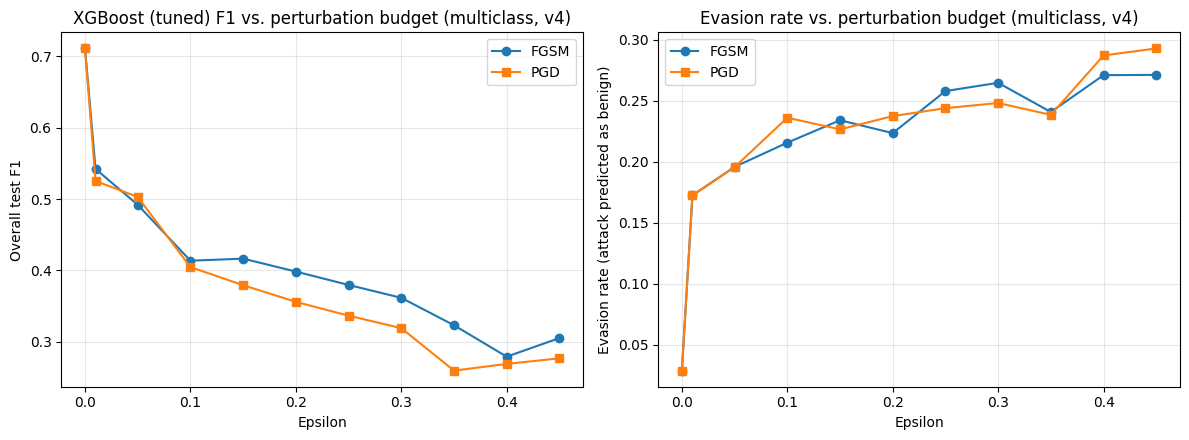

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

eps_vals = [r['epsilon'] for r in results_pgd]
axes[0].plot(eps_vals, [r['overall_f1'] for r in results_fgsm], marker='o', label='FGSM')
axes[0].plot(eps_vals, [r['overall_f1'] for r in results_pgd], marker='s', label='PGD')
axes[0].set_xlabel('Epsilon')
axes[0].set_ylabel('Overall test F1')
axes[0].set_title('XGBoost (tuned) F1 vs. perturbation budget (multiclass, v4)')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(eps_vals, [r['evasion_rate'] for r in results_fgsm], marker='o', label='FGSM')
axes[1].plot(eps_vals, [r['evasion_rate'] for r in results_pgd], marker='s', label='PGD')
axes[1].set_xlabel('Epsilon')
axes[1].set_ylabel('Evasion rate (attack predicted as benign)')
axes[1].set_title('Evasion rate vs. perturbation budget (multiclass, v4)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'attack1_f1_degradation_baseline_{PIPELINE_VERSION}.png', dpi=150)
plt.show()

## 7. Per-class breakdown at a representative epsilon (0.1) -- PGD

In [ ]:
EPS_DETAIL = 0.1
class_names = ['benign', 'backdoor', 'Bruteforce', 'FDI', 'ransomware', 'reverseshell']

X_adv_detail = pgd_attack(surrogate, X_test_scaled, y_test, EPS_DETAIL)
pred_detail = xgb_model.predict(X_adv_detail)

print(f'PGD, epsilon={EPS_DETAIL}')
print(classification_report(y_test, pred_detail, target_names=class_names, digits=4))

print('\nPer-class evasion rate (predicted as benign | true class != benign):')
per_class_evasion_pgd = {}
for cls_idx, cls_name in enumerate(class_names[1:], start=1):
    mask = (y_test.values == cls_idx)
    evasion_rate = (pred_detail[mask] == 0).mean()
    per_class_evasion_pgd[cls_name] = float(evasion_rate)
    print(f'  {cls_name:<14} evasion rate: {evasion_rate:.4f}')

PGD, epsilon=0.1
              precision    recall  f1-score   support

      benign     0.3518    0.6653    0.4602     15745
    backdoor     0.3162    0.4132    0.3582     14445
  Bruteforce     0.2618    0.1127    0.1576     20347
         FDI     0.4134    0.2314    0.2967     15611
  ransomware     0.6648    0.4812    0.5583     15623
reverseshell     0.5949    0.7584    0.6668     15692

    accuracy                         0.4286     97463
   macro avg     0.4338    0.4437    0.4163     97463
weighted avg     0.4269    0.4286    0.4047     97463


Per-class evasion rate (predicted as benign | true class != benign):
  backdoor       evasion rate: 0.4923
  Bruteforce     evasion rate: 0.3927
  FDI            evasion rate: 0.2688
  ransomware     evasion rate: 0.0000
  reverseshell   evasion rate: 0.0000


## 7b. FGSM per-class breakdown (same epsilon, for comparison)

In [ ]:
X_adv_detail_fgsm = fgsm_attack(surrogate, X_test_scaled, y_test, EPS_DETAIL)
pred_detail_fgsm = xgb_model.predict(X_adv_detail_fgsm)

print(f'FGSM, epsilon={EPS_DETAIL}')
print(classification_report(y_test, pred_detail_fgsm, target_names=class_names, digits=4))

print('\nPer-class evasion rate (predicted as benign | true class != benign):')
per_class_evasion_fgsm = {}
for cls_idx, cls_name in enumerate(class_names[1:], start=1):
    mask = (y_test.values == cls_idx)
    evasion_rate = (pred_detail_fgsm[mask] == 0).mean()
    per_class_evasion_fgsm[cls_name] = float(evasion_rate)
    print(f'  {cls_name:<14} evasion rate: {evasion_rate:.4f}')

FGSM, epsilon=0.1
              precision    recall  f1-score   support

      benign     0.3816    0.6907    0.4916     15745
    backdoor     0.3693    0.5320    0.4360     14445
  Bruteforce     0.2636    0.1103    0.1556     20347
         FDI     0.3890    0.2074    0.2705     15611
  ransomware     0.6579    0.4629    0.5435     15623
reverseshell     0.5871    0.7603    0.6626     15692

    accuracy                         0.4433     97463
   macro avg     0.4414    0.4606    0.4266     97463
weighted avg     0.4337    0.4433    0.4136     97463


Per-class evasion rate (predicted as benign | true class != benign):
  backdoor       evasion rate: 0.3968
  Bruteforce     evasion rate: 0.3654
  FDI            evasion rate: 0.2858
  ransomware     evasion rate: 0.0000
  reverseshell   evasion rate: 0.0000


## 8. Statistical validation

Everything above (Sections 5-7) reports single-run point estimates -- one surrogate
(seed=42), one attack generation, one evasion-rate number per epsilon. Given this
project's own precedent (the Optuna tuned-vs-baseline verdict flipped once seed noise
was properly accounted for), the same scrutiny applies here before treating any Attack 1
number as a finding rather than a sample.

Three checks, in order:
- **8a. Seed-robustness**: retrain the surrogate at 5 seeds, report evasion-rate spread
  at eps=0.1 (PGD) -- is the single-seed number representative, or within a wide range?
- **8b. McNemar's test**: is the clean-vs-adversarial degradation in target-model
  correctness statistically significant, or could it be sampling noise on this test set?
  Paired test (same samples, same target model, only the input perturbed), which is the
  statistically correct test for this comparison.
- **8c. Bootstrap confidence interval**: how much would the eps=0.1 PGD evasion rate move
  on a different sample of the same distribution? Reported as a 95% CI, not a bare point
  estimate.

### 8a. Seed-robustness check

Is the eps=0.1 evasion rate stable across surrogate seeds, or was the single-seed
(42) number in Section 7 a lucky/unlucky draw? Retrains the surrogate at 5 seeds and
reports the spread for **both PGD and FGSM** -- same precedent as this project's Optuna
seed-robustness checks, which once caught a false "tuned is worse" verdict driven by
exactly this kind of single-seed noise. Also cross-checks whether PGD reliably beats
FGSM once seed noise is averaged out, since the single-seed sweep in Section 5 showed
FGSM briefly ahead of PGD at a few epsilons -- worth knowing whether that was a real
pattern or seed noise before it goes in the write-up.

In [ ]:
SEEDS_ROBUSTNESS = [42, 7, 123, 2024, 99]
EPS_ROBUSTNESS = 0.1

seed_results = []
for seed in SEEDS_ROBUSTNESS:
    sur_seed = train_surrogate(seed, X_train_scaled, y_train, n_classes=6, verbose=False)

    X_adv_seed_pgd = pgd_attack(sur_seed, X_test_scaled, y_test, EPS_ROBUSTNESS)
    pred_seed_pgd = xgb_model.predict(X_adv_seed_pgd)
    overall_f1_seed_pgd = f1_score(y_test, pred_seed_pgd, average='weighted')
    evasion_seed_pgd = (pred_seed_pgd[attack_mask] == 0).mean()

    X_adv_seed_fgsm = fgsm_attack(sur_seed, X_test_scaled, y_test, EPS_ROBUSTNESS)
    pred_seed_fgsm = xgb_model.predict(X_adv_seed_fgsm)
    overall_f1_seed_fgsm = f1_score(y_test, pred_seed_fgsm, average='weighted')
    evasion_seed_fgsm = (pred_seed_fgsm[attack_mask] == 0).mean()

    seed_results.append({
        'seed': seed,
        'pgd_overall_f1': overall_f1_seed_pgd, 'pgd_evasion_rate': evasion_seed_pgd,
        'fgsm_overall_f1': overall_f1_seed_fgsm, 'fgsm_evasion_rate': evasion_seed_fgsm,
    })
    print(f'  seed={seed:<5}  PGD: f1={overall_f1_seed_pgd:.4f} evasion={evasion_seed_pgd:.4f}  |  '
          f'FGSM: f1={overall_f1_seed_fgsm:.4f} evasion={evasion_seed_fgsm:.4f}')

pgd_evasion_vals = np.array([r['pgd_evasion_rate'] for r in seed_results])
pgd_f1_vals = np.array([r['pgd_overall_f1'] for r in seed_results])
fgsm_evasion_vals = np.array([r['fgsm_evasion_rate'] for r in seed_results])
fgsm_f1_vals = np.array([r['fgsm_overall_f1'] for r in seed_results])

def _report(name, vals):
    print(f'{name}: mean={vals.mean():.4f}  std={vals.std():.4f}  '
          f'min={vals.min():.4f}  max={vals.max():.4f}  range={vals.max()-vals.min():.4f}')

print(f'\n--- PGD across {len(SEEDS_ROBUSTNESS)} seeds (eps={EPS_ROBUSTNESS}) ---')
_report('Evasion rate', pgd_evasion_vals)
_report('Overall F1  ', pgd_f1_vals)

print(f'\n--- FGSM across {len(SEEDS_ROBUSTNESS)} seeds (eps={EPS_ROBUSTNESS}) ---')
_report('Evasion rate', fgsm_evasion_vals)
_report('Overall F1  ', fgsm_f1_vals)

# Cross-check: does PGD reliably beat FGSM once seed noise is averaged out, even though
# a single seed (42) showed FGSM briefly ahead of PGD at some epsilons in Section 5?
pgd_wins = int((pgd_evasion_vals > fgsm_evasion_vals).sum())
print(f'\nPGD evasion > FGSM evasion in {pgd_wins}/{len(SEEDS_ROBUSTNESS)} seeds '
      f'(mean PGD={pgd_evasion_vals.mean():.4f} vs mean FGSM={fgsm_evasion_vals.mean():.4f})')

seed_robustness_multiclass = {
    'eps': EPS_ROBUSTNESS, 'seeds': SEEDS_ROBUSTNESS, 'per_seed_results': seed_results,
    'pgd_evasion_mean': float(pgd_evasion_vals.mean()), 'pgd_evasion_std': float(pgd_evasion_vals.std()),
    'pgd_evasion_min': float(pgd_evasion_vals.min()), 'pgd_evasion_max': float(pgd_evasion_vals.max()),
    'pgd_overall_f1_mean': float(pgd_f1_vals.mean()), 'pgd_overall_f1_std': float(pgd_f1_vals.std()),
    'fgsm_evasion_mean': float(fgsm_evasion_vals.mean()), 'fgsm_evasion_std': float(fgsm_evasion_vals.std()),
    'fgsm_evasion_min': float(fgsm_evasion_vals.min()), 'fgsm_evasion_max': float(fgsm_evasion_vals.max()),
    'fgsm_overall_f1_mean': float(fgsm_f1_vals.mean()), 'fgsm_overall_f1_std': float(fgsm_f1_vals.std()),
    'pgd_beats_fgsm_seed_count': pgd_wins,
}

for name, vals in [('PGD evasion', pgd_evasion_vals), ('FGSM evasion', fgsm_evasion_vals)]:
    if vals.std() > 0.05:
        print(f'\nNOTE: {name}-rate std > 0.05 across seeds -- the single-seed (42) number '
              f'in Section 7 should be reported with this spread, not treated as a fixed value.')
    else:
        print(f'\n{name} rate is stable across seeds (std <= 0.05) -- the single-seed (42) '
              f'result in Section 7 is reasonably representative.')

  seed=42     PGD: f1=0.4047 evasion=0.2362  |  FGSM: f1=0.4136 evasion=0.2157
  seed=7      PGD: f1=0.3539 evasion=0.2351  |  FGSM: f1=0.3846 evasion=0.2432
  seed=123    PGD: f1=0.4037 evasion=0.2260  |  FGSM: f1=0.3827 evasion=0.2458
  seed=2024   PGD: f1=0.3420 evasion=0.1746  |  FGSM: f1=0.3464 evasion=0.2182
  seed=99     PGD: f1=0.4106 evasion=0.2266  |  FGSM: f1=0.4111 evasion=0.2203

--- PGD across 5 seeds (eps=0.1) ---
Evasion rate: mean=0.2197  std=0.0230  min=0.1746  max=0.2362  range=0.0616
Overall F1  : mean=0.3830  std=0.0290  min=0.3420  max=0.4106  range=0.0686

--- FGSM across 5 seeds (eps=0.1) ---
Evasion rate: mean=0.2286  std=0.0130  min=0.2157  max=0.2458  range=0.0301
Overall F1  : mean=0.3877  std=0.0243  min=0.3464  max=0.4136  range=0.0672

PGD evasion > FGSM evasion in 2/5 seeds (mean PGD=0.2197 vs mean FGSM=0.2286)

PGD evasion rate is stable across seeds (std <= 0.05) -- the single-seed (42) result in Section 7 is reasonably representative.

FGSM evasion ra

### 8b. McNemar's test

Is the clean-vs-adversarial degradation in target-model correctness statistically
significant, or could it be sampling noise on this test set? Paired test (same samples,
same target model, only the input perturbed) -- the statistically correct test for this
comparison, using the seed=42 surrogate's PGD adversarial examples from Section 7
(`X_adv_detail`, `pred_detail`).

b = samples the target got right when clean but wrong under attack (successful
evasions); c = the reverse (unusual, but tracked for completeness). Uses the exact
binomial test when b+c is small, and a continuity-corrected chi-square test otherwise --
standard McNemar's test convention.

In [ ]:
def mcnemar_test(y_true, pred_clean, pred_adv):
    y_true_arr = y_true.values if hasattr(y_true, 'values') else y_true
    correct_clean = (pred_clean == y_true_arr)
    correct_adv = (pred_adv == y_true_arr)
    b = int(np.sum(correct_clean & ~correct_adv))   # clean correct, adversarial wrong
    c = int(np.sum(~correct_clean & correct_adv))   # clean wrong, adversarial correct
    n = b + c
    if n == 0:
        return {'b': b, 'c': c, 'n_discordant': n, 'statistic': None, 'p_value': 1.0,
                'method': 'degenerate (b+c=0, no discordant pairs)'}
    if n < 25:
        from scipy.stats import binomtest
        result = binomtest(min(b, c), n, 0.5, alternative='two-sided')
        return {'b': b, 'c': c, 'n_discordant': n, 'statistic': None,
                'p_value': float(result.pvalue), 'method': 'exact binomial'}
    else:
        from scipy.stats import chi2
        statistic = (abs(b - c) - 1) ** 2 / n
        p_value = float(1 - chi2.cdf(statistic, df=1))
        return {'b': b, 'c': c, 'n_discordant': n, 'statistic': float(statistic),
                'p_value': p_value, 'method': 'chi-square (continuity corrected)'}


pred_clean_target = xgb_model.predict(X_test_scaled)
mcnemar_result = mcnemar_test(y_test, pred_clean_target, pred_detail)

print(f"McNemar's test -- clean vs. PGD-adversarial (eps={EPS_DETAIL}) predictions:")
print(f'  b (clean correct -> adversarial wrong): {mcnemar_result["b"]}')
print(f'  c (clean wrong -> adversarial correct): {mcnemar_result["c"]}')
print(f'  discordant pairs (b+c): {mcnemar_result["n_discordant"]}')
print(f'  method: {mcnemar_result["method"]}')
if mcnemar_result['statistic'] is not None:
    print(f'  test statistic: {mcnemar_result["statistic"]:.4f}')
print(f'  p-value: {mcnemar_result["p_value"]:.6g}')

alpha = 0.05
if mcnemar_result['p_value'] < alpha:
    print(f'\nResult: significant at alpha={alpha} -- the clean-vs-adversarial degradation '
          f'is a real effect, not sampling noise on this test set.')
else:
    print(f'\nResult: NOT significant at alpha={alpha} -- with this many discordant pairs, '
          f'the observed degradation could plausibly be noise. Treat the eps={EPS_DETAIL} '
          f'evasion finding cautiously.')

McNemar's test -- clean vs. PGD-adversarial (eps=0.1) predictions:
  b (clean correct -> adversarial wrong): 36884
  c (clean wrong -> adversarial correct): 9556
  discordant pairs (b+c): 46440
  method: chi-square (continuity corrected)
  test statistic: 16080.2095
  p-value: 0

Result: significant at alpha=0.05 -- the clean-vs-adversarial degradation is a real effect, not sampling noise on this test set.


### 8c. Bootstrap confidence interval

How much would the eps=0.1 PGD evasion rate (Section 7) move on a different sample of
the same distribution? Resamples the attack-class test subset with replacement to
estimate a 95% CI, rather than reporting a bare point estimate.

In [ ]:
def bootstrap_evasion_ci(pred, attack_mask_arr, n_boot=2000, ci=0.95, random_state=RANDOM_STATE):
    rng = np.random.RandomState(random_state)
    pred_attack = pred[attack_mask_arr]
    n = len(pred_attack)
    boot_rates = np.empty(n_boot)
    for b in range(n_boot):
        sample_idx = rng.randint(0, n, size=n)
        boot_rates[b] = (pred_attack[sample_idx] == 0).mean()
    alpha = (1 - ci) / 2
    lower = float(np.percentile(boot_rates, alpha * 100))
    upper = float(np.percentile(boot_rates, (1 - alpha) * 100))
    point = float((pred_attack == 0).mean())
    return point, lower, upper, boot_rates


evasion_point, evasion_ci_lower, evasion_ci_upper, _ = bootstrap_evasion_ci(
    pred_detail, attack_mask, n_boot=2000, ci=0.95, random_state=RANDOM_STATE)

print(f'PGD evasion rate (eps={EPS_DETAIL}), n_attack_samples={attack_mask.sum()}:')
print(f'  point estimate: {evasion_point:.4f}')
print(f'  95% bootstrap CI: [{evasion_ci_lower:.4f}, {evasion_ci_upper:.4f}]')
print(f'  CI width: {evasion_ci_upper - evasion_ci_lower:.4f}')

statistical_validation_multiclass = {
    'seed_robustness': seed_robustness_multiclass,
    'mcnemar': mcnemar_result,
    'bootstrap_evasion_ci': {
        'eps': EPS_DETAIL, 'point': evasion_point,
        'ci_lower': evasion_ci_lower, 'ci_upper': evasion_ci_upper, 'n_boot': 2000, 'ci_level': 0.95,
    },
}

PGD evasion rate (eps=0.1), n_attack_samples=81718:
  point estimate: 0.2362
  95% bootstrap CI: [0.2334, 0.2390]
  CI width: 0.0057


## Notes

The v3/pre-leakage-fix run's reported numbers (e.g. XGBoost F1=0.9989, PGD evasion
~20%) are from the leakage-inflated iteration and are not comparable to this run's
numbers -- this notebook's results are the honest, current baseline for Attack 1.

Physics-immunity is visible directly in the per-class evasion tables above (Section 7 /
7b) rather than as a separate computed metric, consistent with the original reference
notebook's design -- watch for FDI/ransomware/reverseshell evasion staying low relative
to backdoor/Bruteforce, echoing the physics-feature resilience pattern already
established elsewhere in the dissertation.

## Save Attack 1 results to disk

Filenames tagged with `PIPELINE_VERSION` (`v4`), consistent with the rest of the
pipeline's versioning discipline.

## Comparison: baseline (untuned) vs Optuna-tuned XGBoost under identical attacks


In [ ]:
# Direct comparison against the original NB3 run (Optuna-tuned XGBoost, F1=0.7110),
# if attack1_results_v4.pkl from that run is present in the same directory.
import os as _os

_tuned_path = f'attack1_results_{PIPELINE_VERSION}.pkl'
if _os.path.exists(_tuned_path):
    tuned = joblib.load(_tuned_path)
    print('=' * 78)
    print('BASELINE (untuned) vs TUNED XGBoost -- identical attack methodology')
    print('=' * 78)
    print(f"{'':20} {'Baseline':>12} {'Tuned':>12} {'Diff':>10}")
    print(f"{'Clean test F1':20} {clean_test_f1:>12.4f} {tuned['clean_test_f1']:>12.4f} "
          f"{clean_test_f1-tuned['clean_test_f1']:>+10.4f}")
    print(f"{'Surrogate agreement':20} {sur_target_agreement:>12.4f} "
          f"{tuned['surrogate_target_agreement']:>12.4f} "
          f"{sur_target_agreement-tuned['surrogate_target_agreement']:>+10.4f}")
    print()
    print('PGD evasion rate by epsilon:')
    print(f"{'eps':>6} {'Baseline':>12} {'Tuned':>12} {'Diff (pp)':>12}")
    tuned_by_eps = {r['epsilon']: r['evasion_rate'] for r in tuned['results_pgd']}
    for r in results_pgd:
        eps = r['epsilon']
        base_ev = r['evasion_rate']
        tuned_ev = tuned_by_eps.get(eps)
        if tuned_ev is not None:
            print(f"{eps:>6.2f} {base_ev*100:>11.2f}% {tuned_ev*100:>11.2f}% "
                  f"{(base_ev-tuned_ev)*100:>+11.2f}")
    print()
    print('Per-class PGD evasion at eps=0.10:')
    print(f"{'Class':<14} {'Baseline':>12} {'Tuned':>12} {'Diff (pp)':>12}")
    for cls, base_ev in per_class_evasion_pgd.items():
        tuned_ev = tuned['per_class_evasion_pgd_eps01'].get(cls)
        if tuned_ev is not None:
            print(f"{cls:<14} {base_ev*100:>11.2f}% {tuned_ev*100:>11.2f}% "
                  f"{(base_ev-tuned_ev)*100:>+11.2f}")
    print()
    print('Interpretation guide: small, evenly-signed diffs across classes suggest the')
    print('choice of tuned-vs-baseline model does not change which classes are')
    print('physics-immune or the budget-dependence finding -- only the exact evasion')
    print('percentages. Large diffs concentrated in specific classes, or a sign flip in')
    print('which classes show 0.00% evasion, would mean the tuned/baseline choice')
    print('materially changes the qualitative findings and needs to be resolved before')
    print('trusting either version of Chapter 6.')
else:
    print(f'{_tuned_path} not found in this directory -- run the original NB3 '
          f'(Optuna-tuned) alongside this one to generate the comparison.')


In [ ]:
import os

joblib.dump({
    'PIPELINE_VERSION': PIPELINE_VERSION,
    'results_fgsm': results_fgsm,
    'results_pgd':  results_pgd,
    'per_class_evasion_pgd_eps01': per_class_evasion_pgd,
    'per_class_evasion_fgsm_eps01': per_class_evasion_fgsm,
    'clean_test_f1': clean_test_f1,
    'surrogate_test_f1': sur_test_f1,
    'surrogate_target_agreement': sur_target_agreement,
    'statistical_validation': statistical_validation_multiclass,
}, f'attack1_results_baseline_{PIPELINE_VERSION}.pkl')

# Save PGD adversarial test examples at eps=0.1 (needed for Defence 1)
EPS_SAVE = 0.1
X_adv_pgd_eps01 = pgd_attack(surrogate, X_test_scaled, y_test, EPS_SAVE)
np.save(f'X_adv_pgd_eps01_baseline_{PIPELINE_VERSION}.npy', X_adv_pgd_eps01)

# Save surrogate model
torch.save(surrogate.state_dict(), f'surrogate_mlp_baseline_{PIPELINE_VERSION}.pt')

print(f'NB3-baseline ({PIPELINE_VERSION}, multiclass, UNTUNED XGBoost) artifacts saved:')
for f in [f'attack1_results_baseline_{PIPELINE_VERSION}.pkl',
          f'X_adv_pgd_eps01_baseline_{PIPELINE_VERSION}.npy',
          f'surrogate_mlp_baseline_{PIPELINE_VERSION}.pt']:
    if os.path.exists(f):
        size = os.path.getsize(f) / 1e6
        print(f'  {f}  ({size:.1f} MB)')

print(f'\nAttack 1 summary (PGD):')
for r in results_pgd:
    print(f"  eps={r['epsilon']:.2f}  Overall F1={r['overall_f1']:.4f}  Evasion={r['evasion_rate']:.4f}")

NB3 (v4, multiclass) artifacts saved:
  attack1_results_v4.pkl  (0.0 MB)
  X_adv_pgd_eps01_v4.npy  (16.8 MB)
  surrogate_mlp_v4.pt  (0.0 MB)

Attack 1 summary (PGD):
  eps=0.00  Overall F1=0.7110  Evasion=0.0286
  eps=0.01  Overall F1=0.5253  Evasion=0.1725
  eps=0.05  Overall F1=0.5029  Evasion=0.1956
  eps=0.10  Overall F1=0.4047  Evasion=0.2362
  eps=0.15  Overall F1=0.3793  Evasion=0.2266
  eps=0.20  Overall F1=0.3560  Evasion=0.2375
  eps=0.25  Overall F1=0.3366  Evasion=0.2440
  eps=0.30  Overall F1=0.3192  Evasion=0.2482
  eps=0.35  Overall F1=0.2597  Evasion=0.2385
  eps=0.40  Overall F1=0.2690  Evasion=0.2873
  eps=0.45  Overall F1=0.2769  Evasion=0.2930
